# From a scan to a sketch: sections, lines and arcs, silhouettes, DXF and STEP

Reverse engineering a turned or prismatic part starts from a drawing, not from its faces (roadmap §7.6): `slice(chain=True)` and `sections` return **ordered polylines**, `fit_curves` turns them into **lines, arcs and circles** within a tolerance, `silhouette` gives the **outline** of the part seen along a direction (with a clearance offset), and the fitted sketch is written as **DXF** for a CAD sketch or as **STEP curves**, beside `write_step_elements` for fitted primitives as solids. See [slice](https://loumalouomega.github.io/meshioplusplus/slice), [fit_curves](https://loumalouomega.github.io/meshioplusplus/fit_curves), [silhouette](https://loumalouomega.github.io/meshioplusplus/silhouette) and [DXF](https://loumalouomega.github.io/meshioplusplus/formats/dxf).

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()


def render(panels, title, size=(1500, 520), cmap='coolwarm', clim=None, rgb=False):
    """PyVista renders of (mesh, scalar or None, subtitle) panels, embedded
    through matplotlib; a matplotlib scatter when GL is unavailable."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, scalar, sub) in enumerate(panels):
            pl.subplot(0, i)
            path = os.path.join(WORK, f'view{i}.vtu')
            mp.write(path, mesh)
            grid = pv.read(path)
            if rgb and 'red' in grid.array_names:
                colours = np.stack([grid['red'], grid['green'], grid['blue']], axis=1)
                pl.add_mesh(grid, scalars=colours, rgb=True, show_edges=False)
            elif scalar is not None and scalar in grid.array_names:
                pl.add_mesh(grid, scalars=scalar, cmap=cmap, clim=clim, show_edges=False,
                            scalar_bar_args={'title': scalar})
            else:
                pl.add_mesh(grid, color='#90caf9', show_edges=True, edge_color='#1f4e79',
                            line_width=0.3)
            pl.add_text(sub, font_size=10)
            pl.camera_position = 'iso'
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.2))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 4.5))
        for i, (mesh, scalar, sub) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            p = np.asarray(mesh.points)
            c = mesh.point_data[scalar] if scalar in mesh.point_data else p[:, 2]
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1, c=c, cmap=cmap)
            ax.set_title(sub)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

def plot_pieces(ax, pieces, colour='C3'):
    """Draw fit_curves' pieces (sketch-frame coordinates) on a matplotlib axis."""
    for p in pieces:
        if p['type'] == 'line':
            (u0, v0), (u1, v1) = p['start'], p['end']
            ax.plot([u0, u1], [v0, v1], color=colour, lw=2)
        else:
            c, r = np.array(p['centre']), p['radius']
            a0 = np.arctan2(*(np.array(p['start']) - c)[::-1])
            sweep = 2 * np.pi if p['type'] == 'circle' else np.radians(p['sweep'])
            t = a0 + np.linspace(0, sweep, 64)
            ax.plot(c[0] + r * np.cos(t), c[1] + r * np.sin(t), color='C2', lw=2)


def to_frame(points, frame):
    """World points into a sketch frame's (u, v): world = M @ local."""
    m = np.asarray(frame, float).reshape(4, 4)
    return (np.asarray(points) - m[:3, 3]) @ m[:3, :3]

## A scanned shaft

A stepped shaft, radius 10 for 30 and radius 6 above, with a 2-radius fillet at the step, revolved from its profile at 128 facets and scanned with 0.004 of noise.

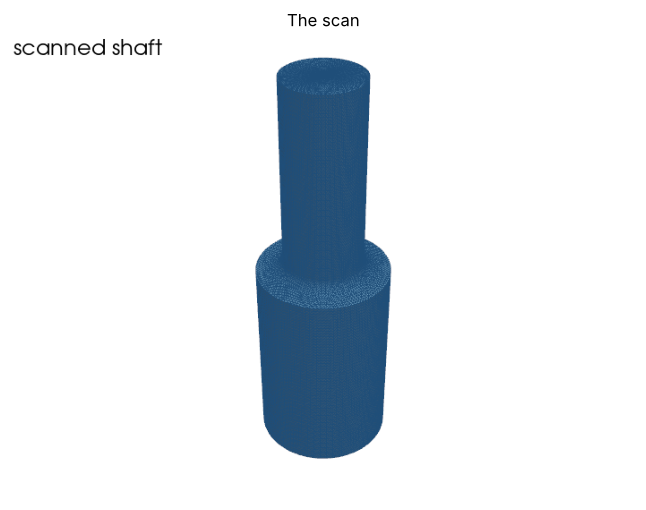

In [2]:
def shaft_profile(step=0.5):
    def line(a, b):
        a, b = np.array(a, float), np.array(b, float)
        n = max(1, int(np.ceil(np.linalg.norm(b - a) / step)))
        return [a + (b - a) * t / n for t in range(n)]
    pts = line((0, 0), (10, 0)) + line((10, 0), (10, 30)) + line((10, 30), (8, 30))
    centre = np.array([8.0, 32.0])
    for k in range(8):
        t = -np.pi / 2 - np.pi / 2 * k / 8
        pts.append(centre + 2 * np.array([np.cos(t), np.sin(t)]))
    pts += line((6, 32), (6, 60)) + line((6, 60), (0, 60)) + [np.array([0.0, 60.0])]
    return np.array(pts)


def revolve(profile, n=128):
    pts, rings = [], []
    for r, z in profile:
        if r < 1e-12:
            rings.append([len(pts)])
            pts.append([0, 0, z])
        else:
            rings.append(list(range(len(pts), len(pts) + n)))
            pts += [[r * np.cos(2 * np.pi * k / n), r * np.sin(2 * np.pi * k / n), z] for k in range(n)]
    tris = []
    for a, b in zip(rings[:-1], rings[1:]):
        for k in range(n):
            if len(a) == 1:
                tris.append([a[0], b[(k + 1) % n], b[k]])
            elif len(b) == 1:
                tris.append([a[k], a[(k + 1) % n], b[0]])
            else:
                tris += [[a[k], a[(k + 1) % n], b[(k + 1) % n]], [a[k], b[(k + 1) % n], b[k]]]
    return mp.Mesh(np.array(pts, float), [('triangle', np.array(tris))])


rng = np.random.default_rng(3)
scan = revolve(shaft_profile())
scan.points = np.asarray(scan.points) + rng.normal(0, 0.004, np.shape(scan.points))
render([(scan, None, 'scanned shaft')], 'The scan', size=(700, 520))

## Chained sections

`slice(chain=True)` welds the cut segments and returns them as ordered `line` cells, one chain per connected curve, with `section:chain` and `section:closed`; the order and orientation are canonical, so the same scan gives the same chains. `sections` cuts at several offsets at once and tags each chain with `section:offset`.

In [3]:
axial = mp.slice(scan, (0, 0, 0), (0, 1, 0), chain=True)
print('axial section:', len(axial.cells[0].data), 'segments,',
      'chains', np.unique(axial.cell_data['section:chain'][0]),
      'closed', np.unique(axial.cell_data['section:closed'][0]))
rings = mp.sections(scan, (0, 0, 1), (10, 20, 45, 55))
print('cross sections at', np.unique(rings.cell_data['section:offset'][0]))

axial section: 903 segments, chains [0] closed [1]
cross sections at [10. 20. 45. 55.]


## Lines, arcs and circles

`fit_curves` splits each chain where its curvature jumps, fits lines and arcs (an algebraic circle refined by a geometric fit), merges neighbours that one curve explains, and intersects adjacent pieces at the corners. A closed chain within the tolerance is one circle. The sketch is stored on the line mesh as `sketch:*` field data (type, parameters, frame), so formats and pipeline steps carry it.

8 lines, 2 arcs, max residual 0.0118
  line   length 20.000
  line   length 29.998
  line   length 2.023
  arc    r = 2.000, sweep 87.2
  line   length 28.072
  line   length 12.001
  line   length 28.060
  arc    r = 1.991, sweep 88.4
  line   length 2.008
  line   length 30.002
cross sections: [('circle', 10.0), ('circle', 10.0), ('circle', 6.0), ('circle', 6.0)]


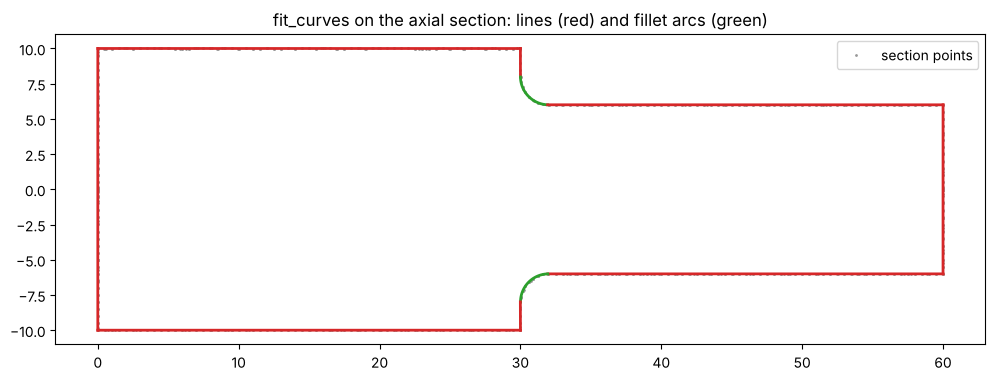

In [4]:
sketch, report = mp.fit_curves(axial, tolerance=0.02, return_report=True)
print(f"{report['num_lines']} lines, {report['num_arcs']} arcs, max residual {report['max_residual']:.4f}")
for p in report['pieces']:
    extra = f"r = {p['radius']:.3f}, sweep {p['sweep']:.1f}" if p['type'] != 'line' else \
        f"length {np.hypot(*np.subtract(p['end'], p['start'])):.3f}"
    print(f"  {p['type']:6s} {extra}")
circles = mp.fit_curves(rings, tolerance=0.02, return_report=True)[1]
print('cross sections:', [(p['type'], round(p['radius'], 3)) for p in circles['pieces']])

fig, ax = plt.subplots(figsize=(12, 4.2))
uv = to_frame(axial.points, report['frames'][0])
ax.plot(uv[:, 0], uv[:, 1], '.', ms=2, color='0.6', label='section points')
plot_pieces(ax, report['pieces'])
ax.set_aspect('equal')
ax.set_title('fit_curves on the axial section: lines (red) and fillet arcs (green)')
ax.legend()
plt.show()

## Silhouette and clearance

`silhouette` projects every triangle onto the plane, unions them exactly (crossings split, a constrained Delaunay triangulation, coverage tested with exact orientation predicates) and returns the outline as chained loops, outer ones counter-clockwise and holes clockwise. `clearance` offsets the outline outward with round corners, the envelope a fixture or a cover needs; `extrude=True` would turn it into a prism.

outline: 1 loop, area 962.04, perimeter 158.29
exact area: 20 x 30 + 12 x 28 + 2 (12 + 4 - pi) = 961.72


with 1.0 clearance: area 1123.47, perimeter 164.57


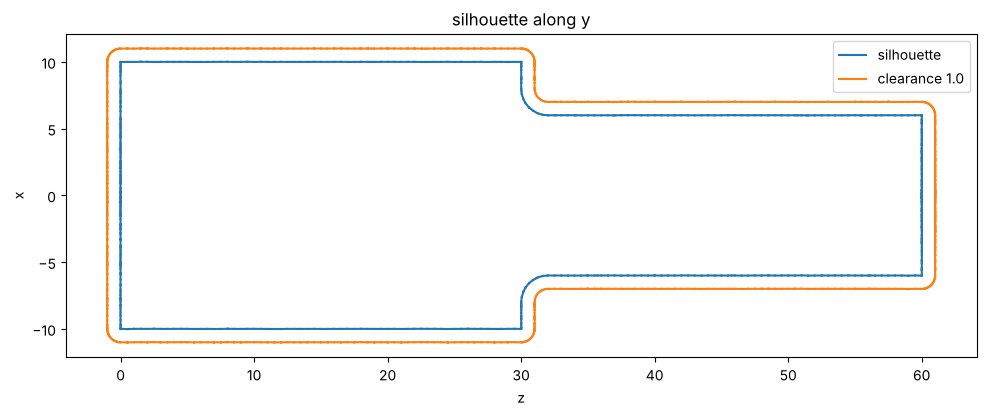

In [5]:
outline, sil = mp.silhouette(scan, (0, 1, 0), return_report=True)
print(f"outline: {sil['num_loops']} loop, area {sil['area']:.2f}, perimeter {sil['perimeter']:.2f}")
print('exact area: 20 x 30 + 12 x 28 + 2 (12 + 4 - pi) =', round(600 + 336 + 2 * (12 + 4 - np.pi), 2))
envelope, env = mp.silhouette(scan, (0, 1, 0), clearance=1.0, return_report=True)
print(f"with 1.0 clearance: area {env['area']:.2f}, perimeter {env['perimeter']:.2f}")

fig, ax = plt.subplots(figsize=(12, 4.2))
for mesh, colour, label in ((outline, 'C0', 'silhouette'), (envelope, 'C1', 'clearance 1.0')):
    p = np.asarray(mesh.points)
    for seg in mesh.cells[0].data:
        ax.plot(p[seg, 2], p[seg, 0], color=colour, lw=1.5)
    ax.plot([], [], color=colour, label=label)
ax.set_aspect('equal')
ax.set_xlabel('z')
ax.set_ylabel('x')
ax.legend()
ax.set_title('silhouette along y')
plt.show()

## DXF for a CAD sketch

The DXF writer emits ASCII R2000 with `LINE`, `ARC`, `CIRCLE`, `LWPOLYLINE` and `SPLINE` entities: a sketch-carrying line mesh becomes its pieces in the sketch's frame, a plain line mesh its segments. The reader takes the same entities back and refuses any other by name. When `ezdxf` is installed, its audit checks the file.

In [6]:
dxf_path = os.path.join(WORK, 'shaft_profile.dxf')
mp.write(dxf_path, sketch)
back = mp.read(dxf_path)
print('read back:', len(back.points), 'points,', len(back.cells[0].data), 'segments')
try:
    import ezdxf
    doc = ezdxf.readfile(dxf_path)
    print('ezdxf audit errors:', len(doc.audit().errors))
    print('entities:', [e.dxftype() for e in doc.modelspace()])
except ImportError:
    print('ezdxf not installed; audit skipped')

read back: 43 points, 40 segments


ezdxf audit errors: 0
entities: ['LINE', 'LINE', 'LINE', 'ARC', 'LINE', 'LINE', 'LINE', 'ARC', 'LINE', 'LINE']


## STEP curves and element solids

`write_step` writes a sketch as `GEOMETRIC_CURVE_SET` wireframe geometry (lines as trimmed `LINE`s, arcs and circles as `CIRCLE`s), which a CAD import shows as a 3-D sketch. `write_step_elements` writes fitted primitives as solids: here the shaft is segmented at its creases, fitted, and its radius-10 cylinder written as a lidded cylinder.

In [7]:
step_path = os.path.join(WORK, 'shaft_profile.step')
mp.write(step_path, sketch)
text = open(step_path).read()
print('curve set:', 'GEOMETRICALLY_BOUNDED_WIREFRAME_SHAPE_REPRESENTATION' in text,
      '| CIRCLE', text.count('CIRCLE('), '| LINE', text.count('LINE('))

fitted = mp.fit_primitives(mp.segment(scan, feature_angle=30), tolerance=1e-3)
types = np.ravel(fitted.field_data['fit:patch_type'])
params = np.ravel(fitted.field_data['fit:patch_params']).reshape(-1, 10)
ids = np.ravel(fitted.field_data['fit:patch_id'])
cyl = [int(i) for i, t, p in zip(ids, types, params) if t == 3 and abs(p[6] - 10) < 0.05]
elements_path = os.path.join(WORK, 'shaft_elements.step')
mp.write_step_elements(elements_path, fitted, patches=cyl)
print('cylinder patch', cyl, 'radius', params[list(ids).index(cyl[0]), 6].round(4), '->',
      open(elements_path).read().count('MANIFOLD_SOLID_BREP'), 'solid')

curve set: True | CIRCLE 2 | LINE 8
cylinder patch [3] radius 10.0001 -> 1 solid
